In [3]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
import libpysal
from esda.moran import Moran, Moran_Local

print("Spatial Autocorrelation Engine (PySAL & ESDA) Active.")

# --- REUSABLE PIPELINE SIMULATION ---
# Generate a synthetic 20x20 spatial grid representing seabed elevation change (BCR)
np.random.seed(42)
x_coords, y_coords = np.meshgrid(np.arange(20), np.arange(20))
x_flat, y_flat = x_coords.flatten(), y_coords.flatten()

# Simulate background noise plus a localized scour hot-spot in the upper right
bcr_values = np.random.normal(0, 0.05, size=x_flat.shape)
hotspot_mask = (x_flat > 12) & (y_flat > 12)
bcr_values[hotspot_mask] += np.random.uniform(0.3, 0.6, size=np.sum(hotspot_mask))

# Create a GeoDataFrame (matching how you will handle vector/point corridor data)
geometry = [Point(x, y) for x, y in zip(x_flat, y_flat)]
gdf = gpd.GeoDataFrame({'bcr': bcr_values}, geometry=geometry)

# 1. Build Spatial Weights Matrix (Queen contiguity / K-Nearest Neighbors)
w = libpysal.weights.KNN.from_dataframe(gdf, k=8)
w.transform = 'r'  # Row-standardize weights

# 2. Compute Global Moran's I
moran_global = Moran(gdf['bcr'], w)
print(f"\nGlobal Moran's I: {moran_global.I:.4f}")
print(f"P-value (significance): {moran_global.p_sim:.4f}")

if moran_global.p_sim < 0.05:
    print("-> Result: Statistically significant spatial clustering detected!")
else:
    print("-> Result: Spatial pattern is random.")

# 3. Compute Local Moran's I (LISA) for hot-spot detection
moran_local = Moran_Local(gdf['bcr'], w)
gdf['lisa_q'] = moran_local.q          # Quadrant (1=HH, 2=LH, 3=LL, 4=HL)
gdf['lisa_p'] = moran_local.p_sim      # Local p-value


Spatial Autocorrelation Engine (PySAL & ESDA) Active.

Global Moran's I: 0.7660
P-value (significance): 0.0010
-> Result: Statistically significant spatial clustering detected!


LISA Cluster Map saved to: /Users/macbookpro2020/niger-delta-phd/07_figures/04_lisa_cluster_map.png


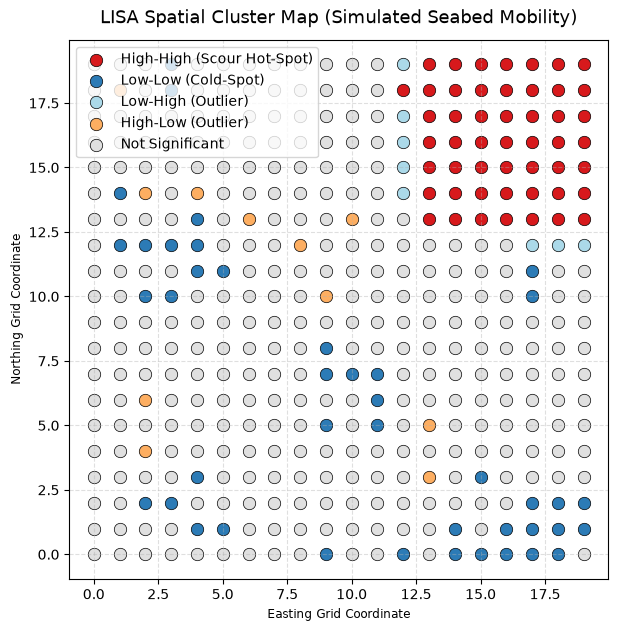

In [4]:
# Filter for statistically significant clusters (p < 0.05)
sig = gdf['lisa_p'] < 0.05

# Assign readable cluster labels
cluster_labels = np.full(len(gdf), 'Not Significant', dtype=object)
cluster_labels[(sig) & (gdf['lisa_q'] == 1)] = 'High-High (Scour Hot-Spot)'
cluster_labels[(sig) & (gdf['lisa_q'] == 3)] = 'Low-Low (Cold-Spot)'
cluster_labels[(sig) & (gdf['lisa_q'] == 2)] = 'Low-High (Outlier)'
cluster_labels[(sig) & (gdf['lisa_q'] == 4)] = 'High-Low (Outlier)'
gdf['cluster'] = cluster_labels

# Define color mapping
color_map = {
    'High-High (Scour Hot-Spot)': '#d7191c',
    'Low-Low (Cold-Spot)': '#2c7bb6',
    'Low-High (Outlier)': '#abd9e9',
    'High-Low (Outlier)': '#fdae61',
    'Not Significant': '#e0e0e0'
}

# Plot the LISA Cluster Map
fig, ax = plt.subplots(figsize=(8, 7))
for label, color in color_map.items():
    subset = gdf[gdf['cluster'] == label]
    if not subset.empty:
        subset.plot(ax=ax, color=color, label=label, markersize=80, edgecolor='black', linewidth=0.5)

plt.title("LISA Spatial Cluster Map (Simulated Seabed Mobility)", fontsize=13, pad=12)
plt.xlabel("Easting Grid Coordinate")
plt.ylabel("Northing Grid Coordinate")
plt.legend(loc='upper left', frameon=True)
plt.grid(True, linestyle='--', alpha=0.4)

# Save output figure to your 07_figures tier
home_path = os.path.expanduser("~")
fig_path = os.path.join(home_path, "niger-delta-phd", "07_figures", "04_lisa_cluster_map.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"LISA Cluster Map saved to: {fig_path}")

plt.show()
